In [ ]:
!zip -r resunet_swinseg_mod_1_outputs.zip /content/resunet_swinseg_mod1_long_multiskip_outputs

  adding: content/resunet_swinseg_mod1_long_multiskip_outputs/ (stored 0%)
  adding: content/resunet_swinseg_mod1_long_multiskip_outputs/resunet_mod1_long_multiskip_best.keras

In [1]:
!unzip -q /content/swinseg.zip -d /content/

TensorFlow: 2.21.0
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Output directory: /content/resunet_swinseg_mod1_long_multiskip_outputs
Total paired samples: 115
Image: 001.jpg
Mask:  001_GT.jpg

Image: 002.jpg
Mask:  002_GT.jpg

Image: 003.jpg
Mask:  003_GT.jpg

Image: 004.jpg
Mask:  004_GT.jpg

Image: 005.jpg
Mask:  005_GT.jpg

Total paired samples: 115
Train: 80 (69.57%)
Validation: 17 (14.78%)
Test: 18 (15.65%)


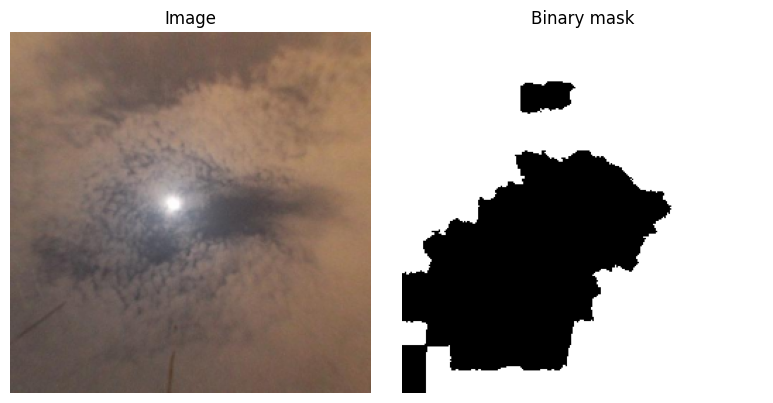

In [4]:
import os
import glob
import random
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEED = 42
IMG_SIZE = (256, 256)
BATCH_SIZE = 2
EPOCHS = 50
LEARNING_RATE = 1e-4
TEST_SIZE = 0.30
BOUNDARY_TOLERANCE_PX = 2
PREDICTION_THRESHOLD = 0.5

DRIVE_ROOT = Path("/content/")
DATA_ROOT = DRIVE_ROOT
IMAGE_DIR = DATA_ROOT / "swinseg" / "images"
MASK_DIR = DATA_ROOT / "swinseg" / "GTmaps"
ZIP_PATH = DRIVE_ROOT / "swinseg.zip"
EXTRACT_DIR = Path("/content/swinseg")
OUTPUT_DIR = DRIVE_ROOT / "resunet_swinseg_mod1_long_multiskip_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
for directory, label in ((IMAGE_DIR, 'IMAGE_DIR'), (MASK_DIR, 'MASK_DIR')):
    if not os.path.isdir(directory):
        raise FileNotFoundError(f'{label} does not exist: {directory}. Update IMAGE_DIR and MASK_DIR.')
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
physical_gpus = tf.config.list_physical_devices('GPU')
for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print('GPU memory growth setting:', exc)
print('TensorFlow:', tf.__version__)
print('Visible GPUs:', physical_gpus if physical_gpus else 'None; available CPU will be used')
print('Output directory:', OUTPUT_DIR)
VALID_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

def list_image_files(directory):
    files = []
    for ext in VALID_EXTENSIONS:
        files.extend(glob.glob(os.path.join(directory, f'*{ext}')))
        files.extend(glob.glob(os.path.join(directory, f'*{ext.upper()}')))
    return sorted(set(files))

def get_pairs(image_dir, mask_dir):
    valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

    image_paths = sorted(
        os.path.join(image_dir, name)
        for name in os.listdir(image_dir)
        if os.path.splitext(name)[1].lower() in valid_exts
    )

    # Map masks using their corresponding image filename
    mask_map = {}

    for name in os.listdir(mask_dir):
        ext = os.path.splitext(name)[1].lower()

        if ext not in valid_exts:
            continue

        stem = os.path.splitext(name)[0]

        # Convert 001_GT to 001
        if stem.lower().endswith("_gt"):
            stem = stem[:-3]

        stem = stem.lower()
        mask_map[stem] = os.path.join(mask_dir, name)

    pairs = []

    for img_path in image_paths:
        stem = os.path.splitext(os.path.basename(img_path))[0].lower()

        if stem in mask_map:
            pairs.append((img_path, mask_map[stem]))
        else:
            print(f"Warning: no mask found for {img_path}")

    return pairs


pairs = get_pairs(IMAGE_DIR, MASK_DIR)

print("Total paired samples:", len(pairs))

for img, mask in pairs[:5]:
    print("Image:", os.path.basename(img))
    print("Mask: ", os.path.basename(mask))
    print()

def load_image_mask(img_path, mask_path):
    img_path = os.fsdecode(img_path)
    mask_path = os.fsdecode(mask_path)
    image = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f'Could not read image: {img_path}')
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f'Could not read binary mask: {mask_path}')
    mask = cv2.resize(mask, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_NEAREST)
    return (image, (mask > 127).astype(np.float32)[..., np.newaxis])

def tf_load_image_mask(img_path, mask_path):
    image, mask = tf.numpy_function(load_image_mask, [img_path, mask_path], [tf.float32, tf.float32])
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return (image, mask)
pairs = get_pairs(IMAGE_DIR, MASK_DIR)
train_pairs, holdout_pairs = train_test_split(pairs, test_size=0.3, random_state=SEED, shuffle=True)
val_pairs, test_pairs = train_test_split(holdout_pairs, test_size=0.5, random_state=SEED, shuffle=True)
_key = lambda pair: os.path.normcase(os.path.abspath(pair[0]))
train_keys = {_key(pair) for pair in train_pairs}
val_keys = {_key(pair) for pair in val_pairs}
test_keys = {_key(pair) for pair in test_pairs}
all_keys = {_key(pair) for pair in pairs}
assert train_keys.isdisjoint(val_keys)
assert train_keys.isdisjoint(test_keys)
assert val_keys.isdisjoint(test_keys)
assert train_keys | val_keys | test_keys == all_keys
assert len(train_pairs) + len(val_pairs) + len(test_pairs) == len(pairs)
manifest = []
for split_name, split_pairs in (('train', train_pairs), ('validation', val_pairs), ('test', test_pairs)):
    for image_path, mask_path in split_pairs:
        manifest.append({'split': split_name, 'image_path': image_path, 'mask_path': mask_path, 'image_filename': Path(image_path).name})
pd.DataFrame(manifest).to_csv(os.path.join(OUTPUT_DIR, 'dataset_split_manifest.csv'), index=False)
print(f'Total paired samples: {len(pairs)}')
for split_name, split_pairs in (('Train', train_pairs), ('Validation', val_pairs), ('Test', test_pairs)):
    print(f'{split_name}: {len(split_pairs)} ({100 * len(split_pairs) / len(pairs):.2f}%)')
AUTOTUNE = tf.data.AUTOTUNE

def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image, mask = (tf.image.flip_left_right(image), tf.image.flip_left_right(mask))
    if tf.random.uniform(()) > 0.5:
        image, mask = (tf.image.flip_up_down(image), tf.image.flip_up_down(mask))
    return (image, mask)

def make_dataset(sample_pairs, training=False):
    image_paths = [pair[0] for pair in sample_pairs]
    mask_paths = [pair[1] for pair in sample_pairs]
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    if training:
        dataset = dataset.shuffle(len(sample_pairs), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)
    if training:
        dataset = dataset.map(augment, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)
train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs, training=False)
_test_image, _test_mask = load_image_mask(*train_pairs[0])
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(_test_image)
axes[1].imshow(_test_mask[..., 0], cmap='gray')
axes[0].set_title('Image')
axes[1].set_title('Binary mask')
for axis in axes:
    axis.axis('off')
plt.tight_layout()
plt.show()


In [5]:
def residual_block_initial(x, filters, strides=(1, 1), name='res_initial'):
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv1')(x)
    y = tf.keras.layers.BatchNormalization(name=f'{name}_bn1')(y)
    y = tf.keras.layers.Activation('relu', name=f'{name}_relu1')(y)
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[1], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv2')(y)
    shortcut = tf.keras.layers.Conv2D(filters, 1, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_shortcut_conv')(x)
    shortcut = tf.keras.layers.BatchNormalization(name=f'{name}_shortcut_bn')(shortcut)
    return tf.keras.layers.Add(name=f'{name}_add')([shortcut, y])

def residual_block(x, filters, strides=(1, 1), name='res_block'):
    input_channels = x.shape[-1]
    y = tf.keras.layers.BatchNormalization(name=f'{name}_bn1')(x)
    y = tf.keras.layers.Activation('relu', name=f'{name}_relu1')(y)
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv1')(y)
    y = tf.keras.layers.BatchNormalization(name=f'{name}_bn2')(y)
    y = tf.keras.layers.Activation('relu', name=f'{name}_relu2')(y)
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[1], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv2')(y)
    if strides[0] != 1 or input_channels != filters:
        shortcut = tf.keras.layers.Conv2D(filters, 1, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_shortcut_conv')(x)
        shortcut = tf.keras.layers.BatchNormalization(name=f'{name}_shortcut_bn')(shortcut)
    else:
        shortcut = x
    return tf.keras.layers.Add(name=f'{name}_add')([shortcut, y])

def project_and_resize(feature, target_tensor, filters, name):
    feature = tf.keras.layers.Conv2D(filters, kernel_size=1, padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_project_conv')(feature)
    feature = tf.keras.layers.BatchNormalization(name=f'{name}_project_bn')(feature)
    feature = tf.keras.layers.Activation('relu', name=f'{name}_project_relu')(feature)
    target_h, target_w = (target_tensor.shape[1], target_tensor.shape[2])
    if target_h is None or target_w is None:
        raise ValueError(f'Static decoder spatial dimensions are required for {name}.')
    feature = tf.keras.layers.Resizing(int(target_h), int(target_w), interpolation='bilinear', name=f'{name}_resize')(feature)
    return feature

def multi_skip_decoder_block(x, skip_features, filters, name):
    x = tf.keras.layers.UpSampling2D(size=(2, 2), interpolation='bilinear', name=f'{name}_upsample')(x)
    projected_skips = [project_and_resize(skip, x, filters, name=f'{name}_skip{i + 1}') for i, skip in enumerate(skip_features)]
    x = tf.keras.layers.Concatenate(name=f'{name}_concat')([x] + projected_skips)
    x = residual_block(x, filters, name=f'{name}_residual')
    return x

def build_resunet_long_multiskip(input_shape=(256, 256, 3), filters=(64, 128, 256, 512)):
    inputs = tf.keras.Input(shape=input_shape, name='image')
    e0 = residual_block_initial(inputs, filters[0], name='encoder_block0')
    e1 = residual_block(e0, filters[1], strides=(2, 1), name='encoder_block1')
    e2 = residual_block(e1, filters[2], strides=(2, 1), name='encoder_block2')
    e3 = residual_block(e2, filters[3], strides=(2, 1), name='encoder_block3')
    bridge = residual_block(e3, filters[3] * 2, strides=(2, 1), name='bridge')
    d3 = multi_skip_decoder_block(bridge, [e3], filters[3], name='decoder_block3')
    d2 = multi_skip_decoder_block(d3, [e2, e3], filters[2], name='decoder_block2')
    d1 = multi_skip_decoder_block(d2, [e1, e2], filters[1], name='decoder_block1')
    d0 = multi_skip_decoder_block(d1, [e0, e1], filters[0], name='decoder_block0')
    logits = tf.keras.layers.Conv2D(1, kernel_size=1, padding='same', activation=None, name='segmentation_logits')(d0)
    return tf.keras.Model(inputs=inputs, outputs=logits, name='ResUNet_LongMultiSkip_Mod1')

def _binary_from_logits(y_true, y_pred):
    y_true = tf.cast(y_true >= 0.5, tf.float32)
    y_pred = tf.cast(y_pred >= 0.0, tf.float32)
    return (y_true, y_pred)

def binary_accuracy_logits(y_true, y_pred):
    y_true, y_pred = _binary_from_logits(y_true, y_pred)
    return tf.reduce_mean(tf.cast(tf.equal(y_true, y_pred), tf.float32))

def dice_coef_logits(y_true, y_pred, smooth=1e-07):
    y_true, y_pred = _binary_from_logits(y_true, y_pred)
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

def iou_coef_logits(y_true, y_pred, smooth=1e-07):
    y_true, y_pred = _binary_from_logits(y_true, y_pred)
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)
PAPER_FILTERS = (64, 128, 256, 512)
model = build_resunet_long_multiskip(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3), filters=PAPER_FILTERS)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss=tf.keras.losses.BinaryCrossentropy(from_logits=True), metrics=[binary_accuracy_logits, dice_coef_logits, iou_coef_logits])
model.summary()


Model: "ResUNet_LongMultiSkip_Mod1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 256, 256,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_con… │ (None, 256, 256,  │      1,728 │ image[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_bn1  │ (None, 256, 256,  │        256 │ encoder_block0_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_sho… │ (None, 256, 256,  │        192 │ image[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_rel… │ (None, 256, 256,  │          0 │ encoder_block0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_sho… │ (None, 256, 256,  │        256 │ encoder_block0_s… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_con… │ (None, 256, 256,  │     36,864 │ encoder_block0_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_add  │ (None, 256, 256,  │          0 │ encoder_block0_s… │
│ (Add)               │ 64)               │            │ encoder_block0_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_bn1  │ (None, 256, 256,  │        256 │ encoder_block0_a… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_rel… │ (None, 256, 256,  │          0 │ encoder_block1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_con… │ (None, 128, 128,  │     73,728 │ encoder_block1_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_bn2  │ (None, 128, 128,  │        512 │ encoder_block1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_sho… │ (None, 128, 128,  │      8,192 │ encoder_block0_a… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_rel… │ (None, 128, 128,  │          0 │ encoder_block1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_sho… │ (None, 128, 128,  │        512 │ encoder_block1_s… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_con… │ (None, 128, 128,  │    147,456 │ encoder_block1_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_add  │ (None, 128, 128,  │          0 │ encoder_block1_s

 Total params: 34,540,737 (131.76 MB)

 Trainable params: 34,517,569 (131.67 MB)

 Non-trainable params: 23,168 (90.50 KB)

Epoch 1/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 349ms/step - binary_accuracy_logits: 0.8458 - dice_coef_logits: 0.8193 - iou_coef_logits: 0.7061 - loss: 0.3823
Epoch 1: val_dice_coef_logits improved from None to 0.59325, saving model to /content/resunet_swinseg_mod1_long_multiskip_outputs/best_resunet_mod1_long_multiskip.weights.h5

Epoch 1: finished saving model to /content/resunet_swinseg_mod1_long_multiskip_outputs/best_resunet_mod1_long_multiskip.weights.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 120s 682ms/step - binary_accuracy_logits: 0.8689 - dice_coef_logits: 0.8542 - iou_coef_logits: 0.7553 - loss: 0.3194 - val_binary_accuracy_logits: 0.4497 - val_dice_coef_logits: 0.5933 - val_iou_coef_logits: 0.4336 - val_loss: 1.9636 - learning_rate: 1.0000e-04
Epoch 2/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 368ms/step - binary_accuracy_logits: 0.8921 - dice_coef_logits: 0.8754 - iou_coef_logits: 0.7873 - loss: 0.2610
Epoch 2: val_dice_coef_logits improved from 0.59325 to 0.72258, saving model to /content/resunet_sw

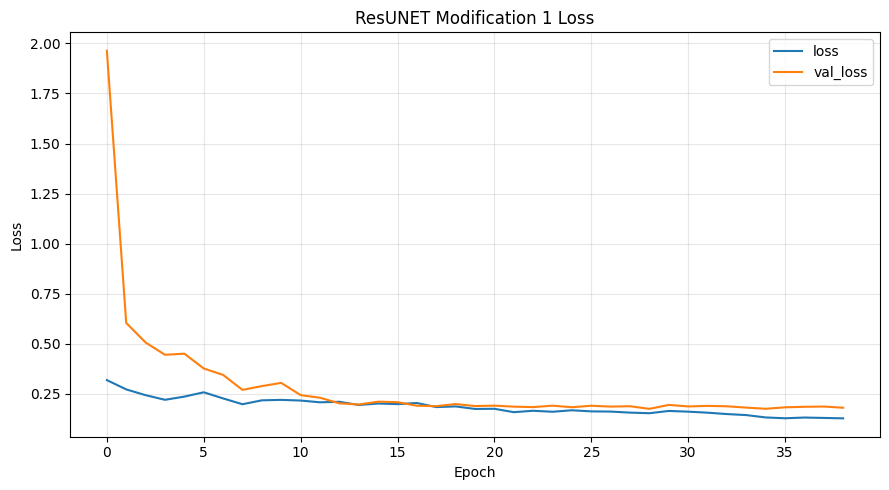

Saved: /content/resunet_swinseg_mod1_long_multiskip_outputs/training_loss.png


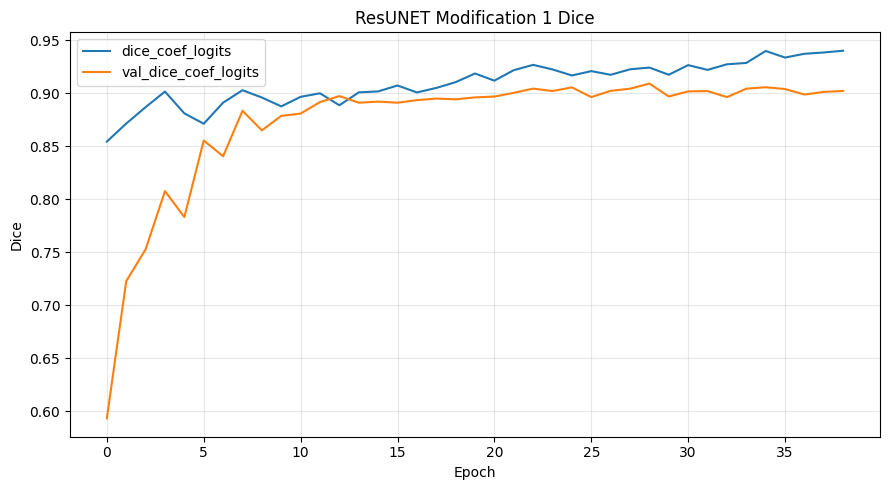

Saved: /content/resunet_swinseg_mod1_long_multiskip_outputs/training_dice.png


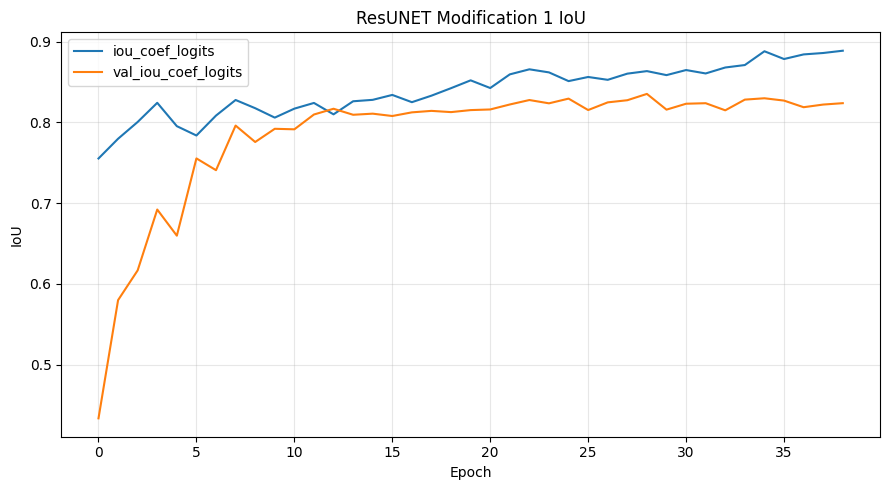

Saved: /content/resunet_swinseg_mod1_long_multiskip_outputs/training_iou.png


In [6]:
BEST_WEIGHTS_PATH = os.path.join(OUTPUT_DIR, 'best_resunet_mod1_long_multiskip.weights.h5')
callbacks = [tf.keras.callbacks.ModelCheckpoint(BEST_WEIGHTS_PATH, monitor='val_dice_coef_logits', mode='max', save_best_only=True, save_weights_only=True, verbose=1), tf.keras.callbacks.EarlyStopping(monitor='val_dice_coef_logits', mode='max', patience=10, restore_best_weights=True, verbose=1), tf.keras.callbacks.ReduceLROnPlateau(monitor='val_dice_coef_logits', mode='max', factor=0.5, patience=4, min_lr=1e-06, verbose=1), tf.keras.callbacks.CSVLogger(os.path.join(OUTPUT_DIR, 'training_log.csv'))]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=1)
if not os.path.isfile(BEST_WEIGHTS_PATH):
    raise FileNotFoundError(f'Best weights were not created: {BEST_WEIGHTS_PATH}')
model.load_weights(BEST_WEIGHTS_PATH)
pd.DataFrame(history.history).to_csv(os.path.join(OUTPUT_DIR, 'training_history.csv'), index_label='epoch')
FINAL_MODEL_PATH = os.path.join(OUTPUT_DIR, 'resunet_mod1_long_multiskip_best.keras')
model.save(FINAL_MODEL_PATH)
print('Saved best-validation model:', FINAL_MODEL_PATH)
print('Saved best weights:', BEST_WEIGHTS_PATH)

def plot_history(history_dict, keys, title, ylabel, filename):
    available = [key for key in keys if key in history_dict]
    if not available:
        return
    plt.figure(figsize=(9, 5))
    for key in available:
        plt.plot(history_dict[key], label=key)
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel(ylabel)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    path = os.path.join(OUTPUT_DIR, filename)
    plt.savefig(path, dpi=160, bbox_inches='tight')
    plt.show()
    print('Saved:', path)
plot_history(history.history, ['loss', 'val_loss'], 'ResUNET Modification 1 Loss', 'Loss', 'training_loss.png')
plot_history(history.history, ['dice_coef_logits', 'val_dice_coef_logits'], 'ResUNET Modification 1 Dice', 'Dice', 'training_dice.png')
plot_history(history.history, ['iou_coef_logits', 'val_iou_coef_logits'], 'ResUNET Modification 1 IoU', 'IoU', 'training_iou.png')


Validation 1/17: 005.jpg
Validation 2/17: 041.jpg
Validation 3/17: 031.jpg
Validation 4/17: 070.jpg
Validation 5/17: 079.jpg
Validation 6/17: 032.jpg
Validation 7/17: 016.jpg
Validation 8/17: 101.jpg
Validation 9/17: 013.jpg
Validation 10/17: 106.jpg
Validation 11/17: 094.jpg
Validation 12/17: 071.jpg
Validation 13/17: 095.jpg
Validation 14/17: 010.jpg
Validation 15/17: 067.jpg
Validation 16/17: 019.jpg
Validation 17/17: 045.jpg

VALIDATION MACRO-AVERAGE METRICS
IoU                   : 0.8339 ± 0.0962
Recall                : 0.9109 ± 0.0835
Precision             : 0.9136 ± 0.0977
Dice_Coefficient      : 0.9063 ± 0.0628
Boundary_F1           : 0.5375 ± 0.1709
Boundary_Recall       : 0.5848 ± 0.1695
Boundary_Precision    : 0.5010 ± 0.1741
Predicted masks: /content/resunet_swinseg_mod1_long_multiskip_outputs/validation_predicted_masks
Per-image metrics: /content/resunet_swinseg_mod1_long_multiskip_outputs/validation_metrics_per_image.csv
Summary metrics: /content/resunet_swinseg_mod1_long

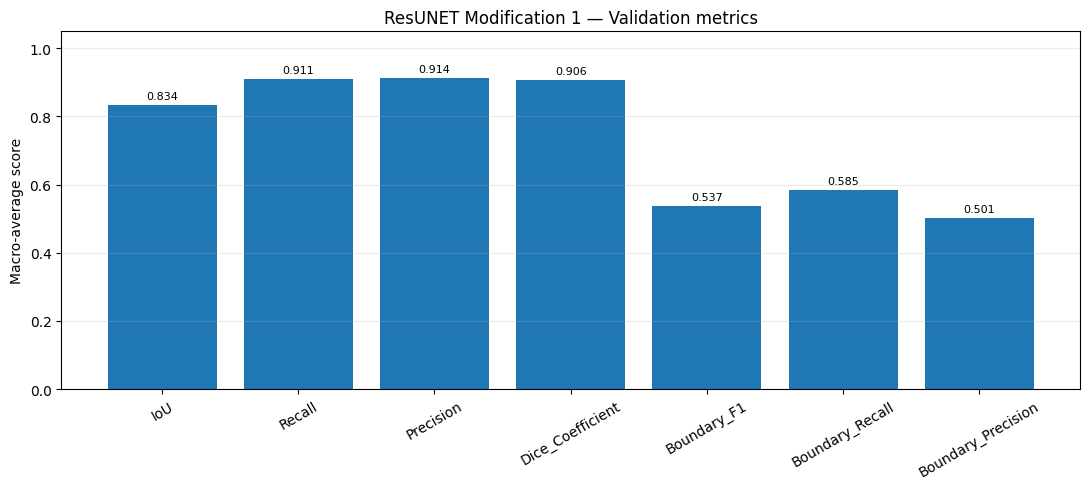

Test 1/18: 110.jpg
Test 2/18: 114.jpg
Test 3/18: 068.jpg
Test 4/18: 113.jpg
Test 5/18: 001.jpg
Test 6/18: 109.jpg
Test 7/18: 054.jpg
Test 8/18: 085.jpg
Test 9/18: 048.jpg
Test 10/18: 073.jpg
Test 11/18: 012.jpg
Test 12/18: 084.jpg
Test 13/18: 082.jpg
Test 14/18: 011.jpg
Test 15/18: 027.jpg
Test 16/18: 023.jpg
Test 17/18: 046.jpg
Test 18/18: 037.jpg

TEST MACRO-AVERAGE METRICS
IoU                   : 0.7924 ± 0.1549
Recall                : 0.8818 ± 0.1796
Precision             : 0.9036 ± 0.0915
Dice_Coefficient      : 0.8751 ± 0.1111
Boundary_F1           : 0.4354 ± 0.1909
Boundary_Recall       : 0.4637 ± 0.2016
Boundary_Precision    : 0.4153 ± 0.1848
Predicted masks: /content/resunet_swinseg_mod1_long_multiskip_outputs/test_predicted_masks
Per-image metrics: /content/resunet_swinseg_mod1_long_multiskip_outputs/test_metrics_per_image.csv
Summary metrics: /content/resunet_swinseg_mod1_long_multiskip_outputs/test_metrics_summary.csv


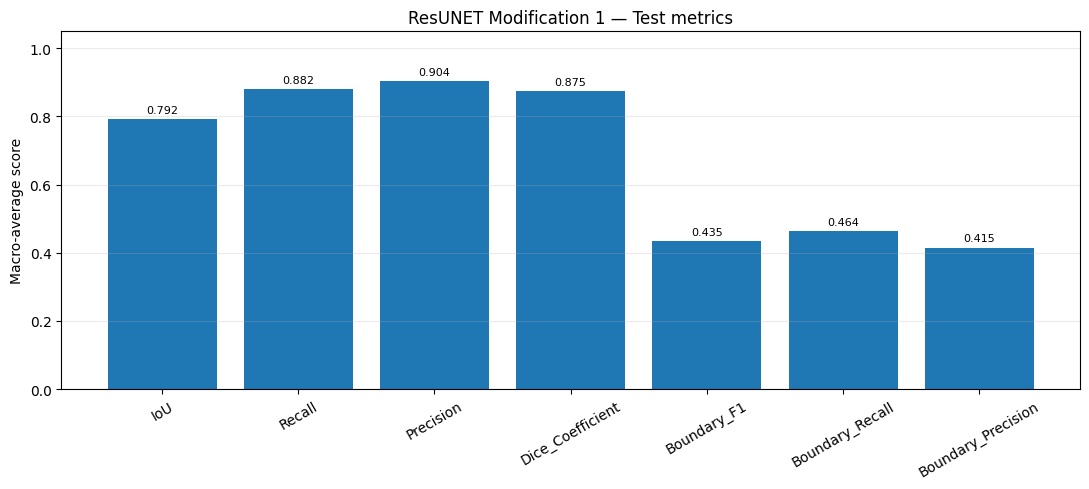


Saved 18 predicted masks for 18 held-out test images.
Output directory: /content/resunet_swinseg_mod1_long_multiskip_outputs


In [7]:
METRIC_COLUMNS = ['IoU', 'Recall', 'Precision', 'Dice_Coefficient', 'Boundary_F1', 'Boundary_Recall', 'Boundary_Precision']

def safe_divide(numerator, denominator):
    return float(numerator / denominator) if denominator else 0.0

def binary_segmentation_metrics(y_true, y_pred):
    gt = np.asarray(y_true, dtype=bool)
    pred = np.asarray(y_pred, dtype=bool)
    tp = int(np.logical_and(gt, pred).sum())
    fp = int(np.logical_and(~gt, pred).sum())
    fn = int(np.logical_and(gt, ~pred).sum())
    precision = safe_divide(tp, tp + fp)
    recall = safe_divide(tp, tp + fn)
    iou = safe_divide(tp, tp + fp + fn)
    dice = safe_divide(2 * tp, 2 * tp + fp + fn)
    gt_u8 = gt.astype(np.uint8)
    pred_u8 = pred.astype(np.uint8)
    erode_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    gt_boundary = (gt_u8 - cv2.erode(gt_u8, erode_kernel, iterations=1)).astype(bool)
    pred_boundary = (pred_u8 - cv2.erode(pred_u8, erode_kernel, iterations=1)).astype(bool)
    kernel_size = 2 * BOUNDARY_TOLERANCE_PX + 1
    tolerance_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
    gt_dilated = cv2.dilate(gt_boundary.astype(np.uint8), tolerance_kernel, iterations=1).astype(bool)
    pred_dilated = cv2.dilate(pred_boundary.astype(np.uint8), tolerance_kernel, iterations=1).astype(bool)
    matched_pred = int(np.logical_and(pred_boundary, gt_dilated).sum())
    matched_gt = int(np.logical_and(gt_boundary, pred_dilated).sum())
    boundary_precision = safe_divide(matched_pred, int(pred_boundary.sum()))
    boundary_recall = safe_divide(matched_gt, int(gt_boundary.sum()))
    boundary_f1 = safe_divide(2 * boundary_precision * boundary_recall, boundary_precision + boundary_recall)
    return {'IoU': iou, 'Recall': recall, 'Precision': precision, 'Dice_Coefficient': dice, 'Boundary_F1': boundary_f1, 'Boundary_Recall': boundary_recall, 'Boundary_Precision': boundary_precision}

def evaluate_split(split_name, split_pairs, save_previews=False):
    prediction_dir = os.path.join(OUTPUT_DIR, f'{split_name}_predicted_masks')
    preview_dir = os.path.join(OUTPUT_DIR, f'{split_name}_prediction_previews')
    os.makedirs(prediction_dir, exist_ok=True)
    if save_previews:
        os.makedirs(preview_dir, exist_ok=True)
    rows = []
    for index, (image_path, mask_path) in enumerate(split_pairs, start=1):
        image, gt_mask = load_image_mask(image_path, mask_path)
        logits = model.predict(image[np.newaxis, ...], verbose=0)[0, ..., 0]
        probabilities = tf.math.sigmoid(logits).numpy()
        pred_mask = probabilities >= PREDICTION_THRESHOLD
        gt_binary = gt_mask[..., 0] >= 0.5
        scores = binary_segmentation_metrics(gt_binary, pred_mask)
        rows.append({'image_name': Path(image_path).name, **scores})
        stem = Path(image_path).stem
        predicted_png = os.path.join(prediction_dir, f'{stem}_prediction.png')
        if not cv2.imwrite(predicted_png, pred_mask.astype(np.uint8) * 255):
            raise IOError(f'Could not save prediction mask: {predicted_png}')
        if save_previews:
            overlay = image.copy()
            overlay[pred_mask] = 0.55 * overlay[pred_mask] + 0.45 * np.array([1.0, 0.0, 0.0])
            fig, axes = plt.subplots(1, 4, figsize=(14, 4))
            axes[0].imshow(image)
            axes[1].imshow(gt_binary, cmap='gray')
            axes[2].imshow(pred_mask, cmap='gray')
            axes[3].imshow(np.clip(overlay, 0, 1))
            for axis, title in zip(axes, ('Image', 'Ground truth', 'Prediction', 'Overlay')):
                axis.set_title(title)
                axis.axis('off')
            fig.suptitle(Path(image_path).name)
            plt.tight_layout()
            fig.savefig(os.path.join(preview_dir, f'{stem}_comparison.png'), dpi=140, bbox_inches='tight')
            plt.close(fig)
        print(f'{split_name.title()} {index}/{len(split_pairs)}: {Path(image_path).name}')
    if len(rows) != len(split_pairs):
        raise RuntimeError(f'Not all {split_name} images were evaluated and saved.')
    per_image = pd.DataFrame(rows)
    per_image_path = os.path.join(OUTPUT_DIR, f'{split_name}_metrics_per_image.csv')
    per_image.to_csv(per_image_path, index=False)
    summary = pd.DataFrame([{'metric': metric, 'macro_average': float(per_image[metric].mean()), 'std': float(per_image[metric].std(ddof=1)) if len(per_image) > 1 else 0.0, 'n_images': len(per_image)} for metric in METRIC_COLUMNS])
    summary_path = os.path.join(OUTPUT_DIR, f'{split_name}_metrics_summary.csv')
    summary.to_csv(summary_path, index=False)
    print(f'\n{split_name.upper()} MACRO-AVERAGE METRICS')
    for _, row in summary.iterrows():
        print(f"{row['metric']:<22}: {row['macro_average']:.4f} ± {row['std']:.4f}")
    print('Predicted masks:', prediction_dir)
    print('Per-image metrics:', per_image_path)
    print('Summary metrics:', summary_path)
    fig, ax = plt.subplots(figsize=(11, 5))
    bars = ax.bar(summary['metric'], summary['macro_average'])
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Macro-average score')
    ax.set_title(f'ResUNET Modification 1 — {split_name.title()} metrics')
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.25)
    for bar, value in zip(bars, summary['macro_average']):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.012, f'{value:.3f}', ha='center', va='bottom', fontsize=8)
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, f'{split_name}_metrics_bar.png'), dpi=160, bbox_inches='tight')
    plt.show()
    return (per_image, summary)
validation_metrics, validation_summary = evaluate_split('validation', val_pairs, save_previews=False)
test_metrics, test_summary = evaluate_split('test', test_pairs, save_previews=True)
print(f'\nSaved {len(test_pairs)} predicted masks for {len(test_pairs)} held-out test images.')
print('Output directory:', OUTPUT_DIR)
